# 04 · Hayashi–Yoshida lead-lag on raw async ticks

The grid-based VECM/IS work attenuates cross-correlation (Epps). HY needs no grid — it sums
return products over overlapping tick intervals — measuring lead-lag directly in real time.
Sign convention (pinned in tests): θ\*<0 ⇒ the first series leads by |θ\*|. The hot loop is
one numba implementation, checked against an independent brute-force O(n·m) oracle; an
optional pybind11 C++ port is kept only as a benchmark (numba beat it).

In [1]:
%load_ext autoreload
%autoreload 2
import datetime as dt, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fxpd.config import TRIANGLES, OUTPUTS_DIR, ensure_dirs
from fxpd.data.processed import get_panel
from fxpd.econo import hy
ensure_dirs(); warnings.simplefilter("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

## Parameters — tweak these

In [2]:
TRIANGLE  = "majors"
HY_START, END = dt.date(2026, 4, 15), dt.date(2026, 7, 20)
EPPS_START, EPPS_END = dt.date(2026, 5, 18), dt.date(2026, 6, 19)
BENCH_DAY = dt.date(2026, 6, 18); LIQUID = (7, 17)
tri = TRIANGLES[TRIANGLE]
hy_dates   = list(pd.bdate_range(HY_START, END).date)
epps_dates = list(pd.bdate_range(EPPS_START, EPPS_END).date)
print(f"{tri} | {len(hy_dates)} lead-lag windows | liquid {LIQUID} UTC")

Triangle(name='majors', cross='EURJPY', leg1='EURUSD', leg2='USDJPY') | 69 lead-lag windows | liquid (7, 17) UTC


## 1 · Backend benchmark (the honest number)

In [3]:
tx, x = hy._series_arrays(tri, "cross", BENCH_DAY, LIQUID)
ty, y = hy._series_arrays(tri, "synth", BENCH_DAY, LIQUID)
th = hy.theta_grid_ns()
hy.hy_leadlag(tx, x, ty, y, th)                      # JIT warm-up

def py_leadlag(tx, x, ty, y, th):                    # same algorithm in plain Python
    d = np.sqrt(np.sum(np.diff(x) ** 2) * np.sum(np.diff(y) ** 2))
    return np.array([hy.hy_cov.py_func(tx, x, ty + t, y) for t in th]) / d

impls = [("python", py_leadlag), ("numba (library)", hy.hy_leadlag)]
try:
    import fxpd_fast                                 # optional: pip install -e ./cpp
    impls.append(("C++ (optional port)", fxpd_fast.hy_leadlag))
except ImportError:
    print("fxpd_fast not built -- C++ row skipped")

def _best(fn, reps=3):
    best = np.inf
    for _ in range(reps):
        s = time.perf_counter(); fn(tx, x, ty, y, th); best = min(best, time.perf_counter() - s)
    return best

rows = []
for name, fn in impls:
    t = _best(fn)
    rows.append({"backend": name, "time_ms": t*1e3, "ticks/s": (len(tx)+len(ty))/t,
                 "Mpairs/s": (len(tx)+len(ty))*len(th)/t/1e6})
bench = pd.DataFrame(rows).set_index("backend")
bench["speedup_vs_python"] = bench["time_ms"].loc["python"] / bench["time_ms"]
print(f"one day: {len(tx):,} cross ticks x {len(ty):,} synth ticks x {len(th)} thetas")
bench

one day: 110,358 cross ticks x 94,668 synth ticks x 23 thetas


,time_ms,ticks/s,Mpairs/s,speedup_vs_python
backend,,,,
python,1867,1.098e+05,2.526,1
numba (library),12.37,1.657e+07,381.2,150.9
C++ (optional port),18.04,1.136e+07,261.4,103.5


## 2 · ρ(θ) lead-lag curves

cross~synth     69 windows (0 skipped)
EURUSD~USDJPY   69 windows (0 skipped)
cross~EURUSD    69 windows (0 skipped)
cross~USDJPY    69 windows (0 skipped)


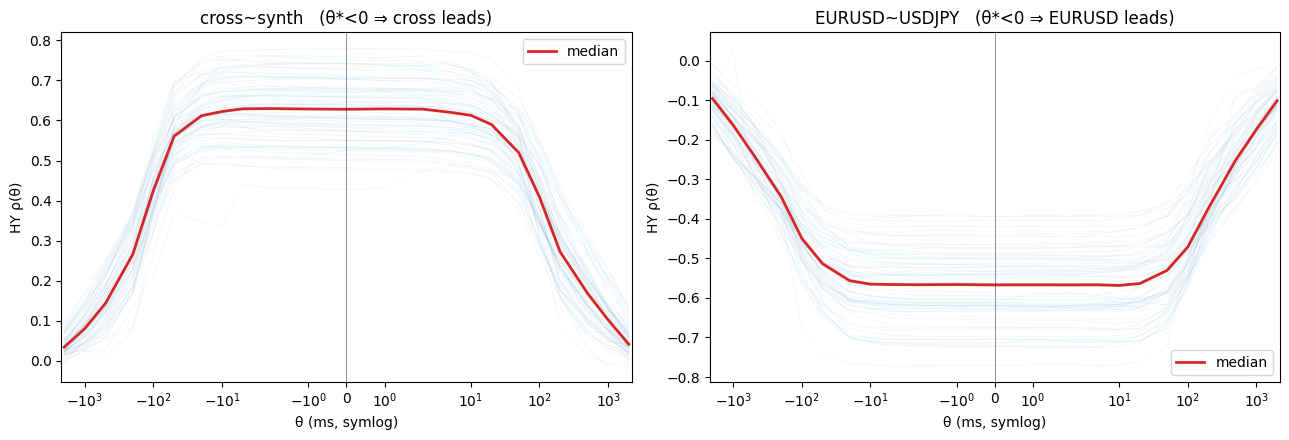

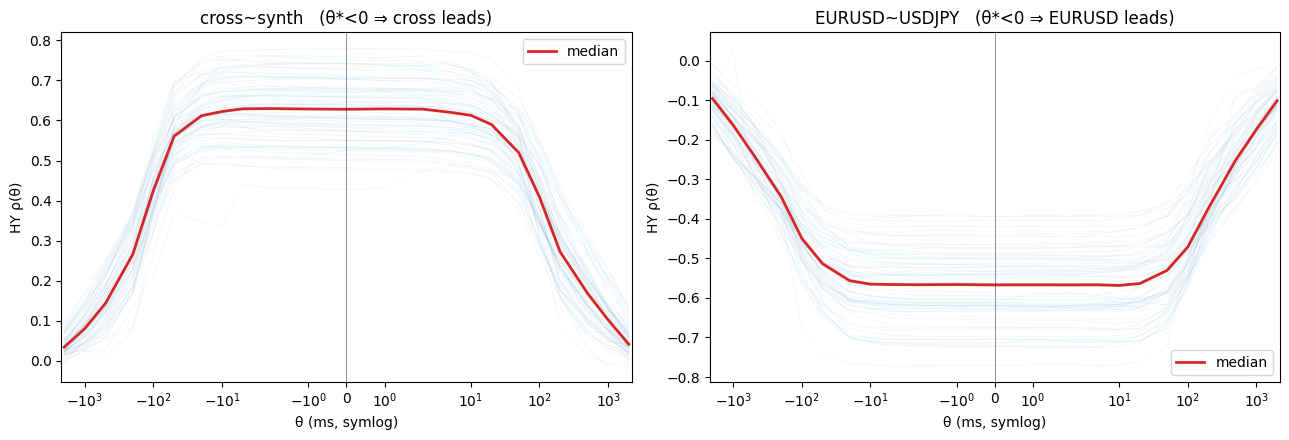

In [4]:
PAIRS = {"cross~synth": ("cross", "synth"),
         f"{tri.leg1}~{tri.leg2}": ("leg1", "leg2"),
         f"cross~{tri.leg1}": ("cross", "leg1"),
         f"cross~{tri.leg2}": ("cross", "leg2")}
res = {name: hy.leadlag_windows(tri, hy_dates, xs, ys, liquid=LIQUID)
       for name,(xs,ys) in PAIRS.items()}
for name,r in res.items():
    print(f"{name:14} {len(r):3d} windows ({r.attrs['skipped']} skipped)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
thm = res["cross~synth"].attrs["thetas_ms"]
for ax, name in zip(axes, ["cross~synth", f"{tri.leg1}~{tri.leg2}"]):
    rho = res[name].attrs["rho"]
    for row in rho: ax.plot(thm, row, color="tab:blue", alpha=0.06, lw=0.6)
    ax.plot(thm, np.median(rho, axis=0), color="tab:red", lw=2, label="median")
    ax.axvline(0, color="k", lw=0.6, alpha=0.5); ax.set_xscale("symlog")
    ax.set_title(f"{name}   (θ*<0 ⇒ {name.split('~')[0]} leads)")
    ax.set_xlabel("θ (ms, symlog)"); ax.set_ylabel("HY ρ(θ)"); ax.legend()
fig.tight_layout(); fig.savefig(OUTPUTS_DIR/"04_rho_curves.png", dpi=130); fig

## 3 · θ\* distribution + sign test

,n,k_neg,frac_neg,binom_p,median_theta_ms,median_S
pair,,,,,,
cross~synth,69,58,0.8406,7.556e-09,-5,0.005528
EURUSD~USDJPY,69,28,0.4058,0.148,2,-0.001353
cross~EURUSD,69,51,0.7391,8.769e-05,-5,0.003377
cross~USDJPY,69,16,0.2319,9.095e-06,5,-0.002518


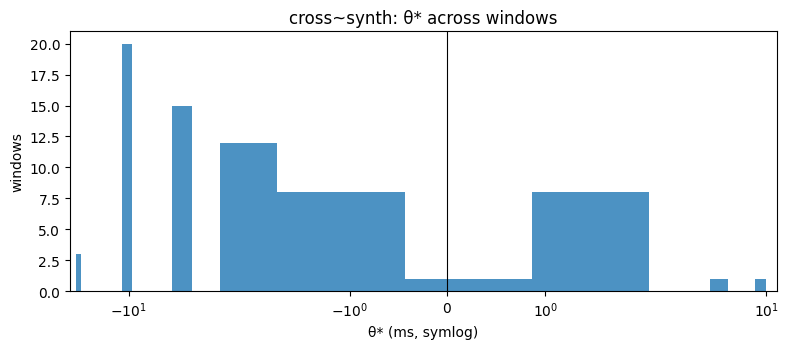

In [5]:
sign_rows = []
for name, r in res.items():
    st = hy.sign_test(r["theta_star_ms"])
    st.update(pair=name, median_theta_ms=float(r["theta_star_ms"].median()),
              median_S=float(r["asymmetry_S"].median()))
    sign_rows.append(st)
sign_tbl = pd.DataFrame(sign_rows).set_index("pair")[
    ["n","k_neg","frac_neg","binom_p","median_theta_ms","median_S"]]

fig, ax = plt.subplots(figsize=(8,3.6))
ax.hist(res["cross~synth"]["theta_star_ms"], bins=len(thm), color="tab:blue", alpha=0.8)
ax.axvline(0, color="k", lw=0.8); ax.set_xscale("symlog")
ax.set_title("cross~synth: θ* across windows"); ax.set_xlabel("θ* (ms, symlog)"); ax.set_ylabel("windows")
fig.tight_layout(); fig.savefig(OUTPUTS_DIR/"04_theta_star_hist.png", dpi=130)
sign_tbl

## 4 · The Epps figure

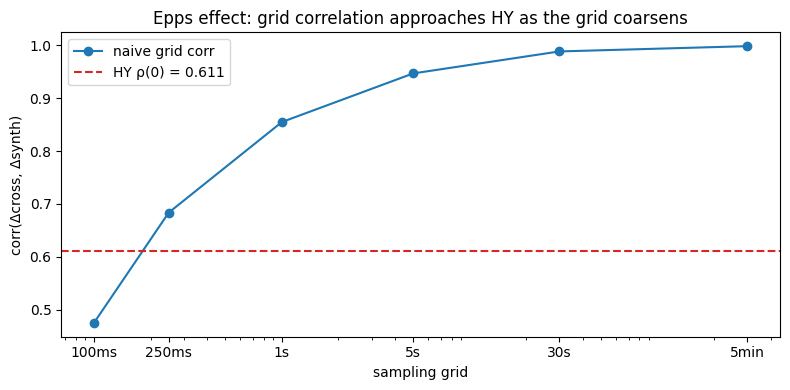

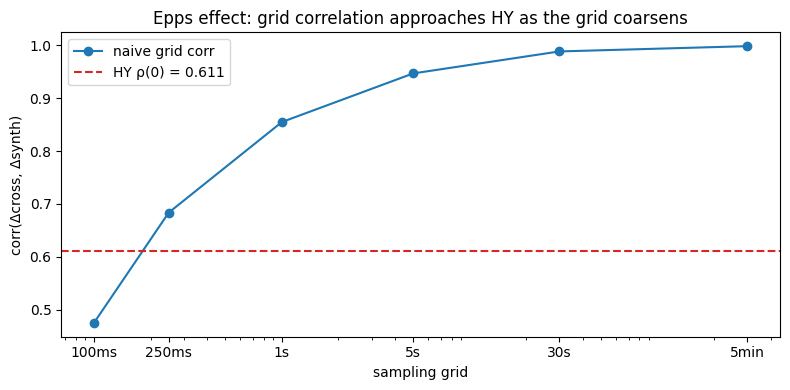

In [6]:
GRIDS = ["100ms","250ms","1s","5s","30s","5min"]
gsec = {"100ms":.1,"250ms":.25,"1s":1,"5s":5,"30s":30,"5min":300}
grid_corr = {}
for g in GRIDS:
    vals = []
    for d in epps_dates:
        try: p = get_panel(tri, d, g, with_age=False)
        except FileNotFoundError: continue
        h = p.index.hour; w = p[(h>=LIQUID[0]) & (h<LIQUID[1])]
        vals.append(w[tri.cross].diff().corr((w[tri.leg1] + w[tri.leg2]).diff()))
    grid_corr[g] = float(np.nanmedian(vals))

res_epps = hy.leadlag_windows(tri, epps_dates, "cross", "synth", liquid=LIQUID)
zero_ix = int(np.where(res_epps.attrs["thetas_ms"] == 0.0)[0][0])
rho0 = float(np.median(res_epps.attrs["rho"][:, zero_ix]))

fig, ax = plt.subplots(figsize=(8,4))
ax.plot([gsec[g] for g in GRIDS], [grid_corr[g] for g in GRIDS], "o-", label="naive grid corr")
ax.axhline(rho0, color="tab:red", ls="--", label=f"HY \u03c1(0) = {rho0:.3f}")
ax.set_xscale("log"); ax.set_xlabel("sampling grid"); ax.set_ylabel("corr(\u0394cross, \u0394synth)")
ax.set_xticks(list(gsec.values())); ax.set_xticklabels(GRIDS)
ax.set_title("Epps effect: grid correlation approaches HY as the grid coarsens"); ax.legend()
fig.tight_layout(); fig.savefig(OUTPUTS_DIR/"04_epps.png", dpi=130); fig

## 5 · Reconciliation with Weeks 2–3

In [7]:
cs = res["cross~synth"]
recon = pd.DataFrame({
    "quantity": ["GG_cross (W3)", "z half-life (W3)", "HY θ* cross~synth (median)",
                 "HY sign test frac(θ*<0)", "HY asymmetry S (median)"],
    "value":    ["~0.65 grid / ~0.57 refresh (07)", "~8 s dynamic (AR(1) proxy ~3.4 s)", f"{cs['theta_star_ms'].median():.0f} ms",
                 f"{(cs['theta_star_ms']<0).mean():.2f}", f"{cs['asymmetry_S'].median():+.3f}"],
}).set_index("quantity")
recon

,value
quantity,
GG_cross (W3),~0.65 grid / ~0.57 refresh (07)
z half-life (W3),~8 s dynamic (AR(1) proxy ~3.4 s)
HY θ* cross~synth (median),-5 ms
HY sign test frac(θ*<0),0.84
HY asymmetry S (median),+0.006


## Takeaway

Direction agrees with 02–03, magnitude is sub-resolution. The cross leads its synthetic in 84% of
69 windows (sign test p=7.6e-9), median θ*=−5 ms — but the ρ(θ) peak is a flat plateau and −5 ms
sits below the ~150–260 ms inter-tick floor, so the honest claim is "cross leads at a
sub-resolution horizon", not a precise 5 ms lead. HY needs no grid, so the *direction* is not a
LOCF artifact — which is why it survives where the grid *level* does not fully (0.65 → 0.57 in
refresh time, 07).

Leg-level: cross leads EURUSD (p=9e-5) but USDJPY leads cross (p=9e-6), and the dollar legs don't
lead each other (p=0.15) — leadership isn't a simple total order.

Epps, made visible: grid correlation is 0.47 @100ms, below HY ρ(0)=0.611, crosses it between 100
and 250 ms and rises to ~1.0 by 5 min. Benchmark (one day, 110k × 95k ticks × 23 θ): plain Python
1.9 s → numba 12.4 ms (151×) → optional C++ port 18.0 ms (104×). Numba beats the C++ port, so the
library runs numba only; the C++ row stays as the honest benchmark. The two-pointer is checked
against a brute-force all-pairs oracle in the tests.